# Classification and Evaluation in NLP

**Text classification** is a common Natural Language Processing (NLP) task where a model assigns a predefined category or label to a piece of text.

Examples include:
- Spam detection
- Sentiment analysis
- News categorization

In this lab, we will learn how to build and evaluate a text classification model.

## Case Study: Sentiment Analysis

Sentiment analysis, also known as opinion mining, its goal is to understand the information present in the text and categorize it as positive, negative, or neutral.

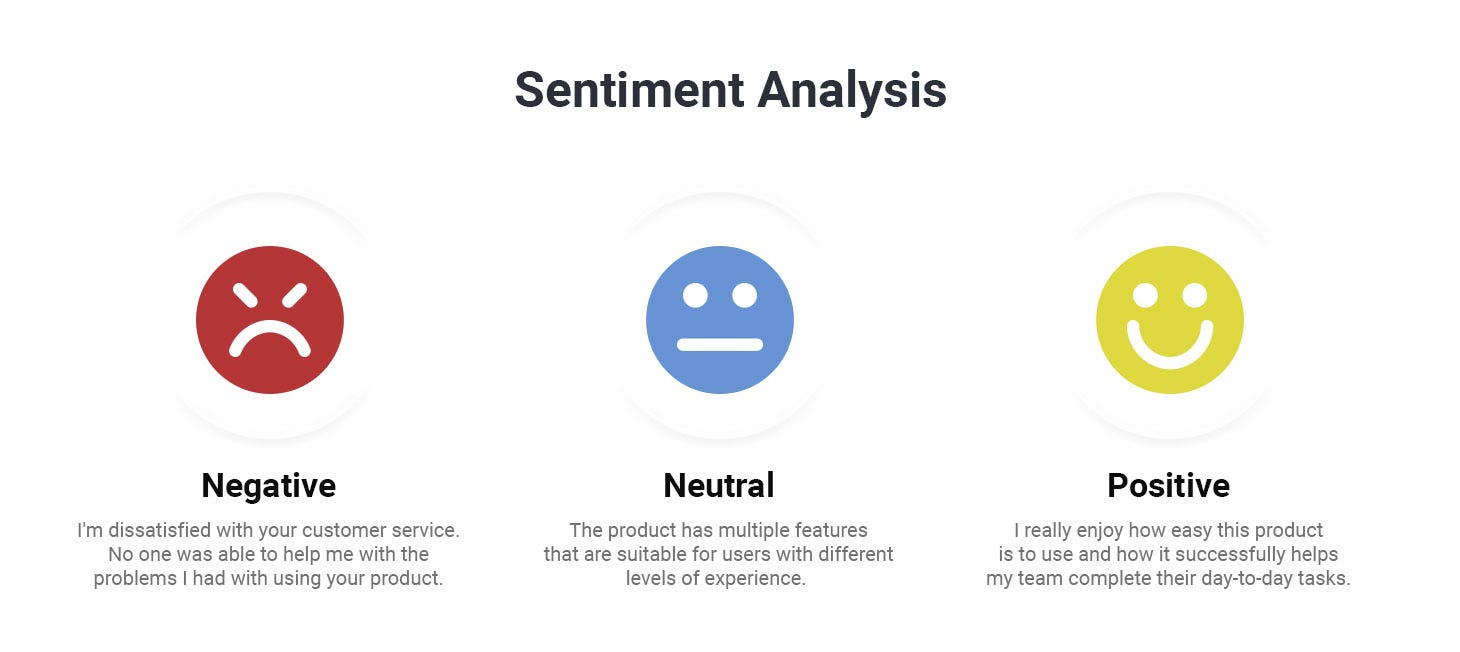

# Disneyland Reviews Dataset
In this lab we'll look into Disneyland Reviews dataset.  
*Link: https://www.kaggle.com/datasets/arushchillar/disneyland-reviews*

The dataset includes 42,000 reviews of 3 Disneyland branches - Paris, California and Hong Kong, posted by visitors on Trip Advisor.

Column Description:

- Review_ID: unique id given to each review
- Rating: ranging from 1 (unsatisfied) to 5 (satisfied)
- Year_Month: when the reviewer visited the theme park
- Reviewer_Location: country of origin of visitor
- Review_Text: comments made by visitor
- Disneyland_Branch: location of Disneyland Park

In [1]:
# Load the dataset
import os
import pandas as pd
import kagglehub

# download the dataset with kagglehub
disney_path = kagglehub.dataset_download("arushchillar/disneyland-reviews")
data = pd.read_csv(os.path.join(disney_path, 'DisneylandReviews.csv'), encoding='latin-1')
data

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong
...,...,...,...,...,...,...
42651,1765031,5,missing,United Kingdom,i went to disneyland paris in july 03 and thou...,Disneyland_Paris
42652,1659553,5,missing,Canada,2 adults and 1 child of 11 visited Disneyland ...,Disneyland_Paris
42653,1645894,5,missing,South Africa,My eleven year old daughter and myself went to...,Disneyland_Paris
42654,1618637,4,missing,United States,"This hotel, part of the Disneyland Paris compl...",Disneyland_Paris


In [2]:
#Check for missing values
data.isna().sum()

Review_ID            0
Rating               0
Year_Month           0
Reviewer_Location    0
Review_Text          0
Branch               0
dtype: int64

In [3]:
# Drop rows with missing values in the relevant columns
data = data.dropna(subset=['Review_Text', 'Rating'])

In [4]:
# Map star ratings to sentiments
data['Sentiment'] = data['Rating'].apply(lambda rating: 'positive' if rating > 3 else ('negative' if rating < 3 else 'neutral'))
data.head()

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch,Sentiment
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong,positive
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong,positive
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong,positive
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong,positive
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong,positive


In [5]:
# Import necessary libraries
import re
import nltk

def preprocess_text(text):

    # 1. Convert text to lowercase
    text = text.lower()

    # 2. Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # 3. Tokenize the text
    words = text.split()

    return ' '.join(words)

# Apply preprocessing to the review text
data['Review_Text'] = data['Review_Text'].apply(preprocess_text)

# Display cleaned reviews
data[['Review_Text', 'Sentiment']].head()

,Review_Text,Sentiment
0,if youve ever been to disneyland anywhere youl...,positive
1,its been a while since d last time we visit hk...,positive
2,thanks god it wasn t too hot or too humid when...,positive
3,hk disneyland is a great compact park unfortun...,positive
4,the location is not in the city took around ho...,positive


In [6]:
# Import necessary libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Split the dataset into training and testing sets
train_data, test_data, train_labels, test_labels = train_test_split(data['Review_Text'], data['Sentiment'], test_size=0.2, random_state=42)


# TF-IDF Vectorization
tfidf_vectorizer = TfidfVectorizer(max_features=1000)  # You can adjust max_features based on your dataset size - limit vocabulary to the 1000 most informative tokens
train_vectors = tfidf_vectorizer.fit_transform(train_data)
test_vectors = tfidf_vectorizer.transform(test_data)

In [7]:
print(f"train_data size: {train_data.shape}")
print(f"test_data size: {test_data.shape}")

train_data size: (34124,)
test_data size: (8532,)


In [8]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Train the Support Vector Machine (SVM) classifier
svm_classifier = SVC(kernel='linear')
svm_classifier.fit(train_vectors, train_labels)

# Predictions on the test set
predictions = svm_classifier.predict(test_vectors)

# Evaluate the model
accuracy = accuracy_score(test_labels, predictions)
print(f"Accuracy: {accuracy:.2f}")

# Display classification report
print("Classification Report:")
print(classification_report(test_labels, predictions))


Accuracy: 0.84
Classification Report:
              precision    recall  f1-score   support

    negative       0.64      0.54      0.58       720
     neutral       0.48      0.18      0.26      1035
    positive       0.88      0.98      0.92      6777

    accuracy                           0.84      8532
   macro avg       0.66      0.56      0.59      8532
weighted avg       0.81      0.84      0.81      8532



# Use Case:  Amazon reviews of unlocked phone analysis

The objective of this use case is to conduct sentiment analysis on Amazon reviews of unlocked phones, categorizing reviews into three classes: positive, negative, and neutral. The goal is to gain a comprehensive understanding of customer opinions and sentiments regarding various unlocked phone models.

- Dataset link: https://www.kaggle.com/datasets/PromptCloudHQ/amazon-reviews-unlocked-mobile-phones

Task1: Load the data and do 5 different preprocessing steps on it

Task2: Use a proper train and test split

Task3: Do Feature Extraction Using TF-IDF

Task4: Train a Naive Bayes Classifier

Task5: Evaluate the model on the Test Set

Task6: Print the Confusion Matrix

## ✅ Solution

### Task 1 – Load the data and apply 5 pre-processing steps

In [9]:
import os, re
import numpy as np
import pandas as pd
import kagglehub

phones_path = kagglehub.dataset_download("PromptCloudHQ/amazon-reviews-unlocked-mobile-phones")
print(os.listdir(phones_path))
phones = pd.read_csv(os.path.join(phones_path, "Amazon_Unlocked_Mobile.csv"))
print(phones.shape)
phones.head()

['Amazon_Unlocked_Mobile.csv']
(413840, 6)


,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0


In [10]:
print(phones.isna().sum())

# keep only the columns we need and drop rows without a review or a rating
phones = phones.dropna(subset=["Reviews", "Rating"])
phones = phones.drop_duplicates(subset=["Reviews", "Rating"])   # identical reviews would leak between train and test
print("\nRows after dropping missing values and duplicates:", len(phones))

# Same mapping as the Disneyland example: 4-5 positive, 3 neutral, 1-2 negative
phones["Sentiment"] = phones["Rating"].apply(
    lambda r: "positive" if r > 3 else ("negative" if r < 3 else "neutral"))
print(phones["Sentiment"].value_counts())

Product Name        0
Brand Name      65171
Price            5933
Rating              0
Reviews            70
Review Votes    12296
dtype: int64

Rows after dropping missing values and duplicates: 163958
Sentiment
positive    104819
negative     44524
neutral      14615
Name: count, dtype: int64


The five pre-processing steps:

1. **Lower-casing** – `Great` and `great` become the same feature.
2. **Removing URLs and HTML tags** – noise that carries no sentiment.
3. **Removing punctuation, digits and special characters** – keep letters only.
4. **Stop-word removal** – drop very common words (*the, is, and…*), **but keep negations** (*not, no, nor, don't…*): "not good" and "good" must stay different for sentiment analysis.
5. **Lemmatization** – reduce words to their dictionary form (*batteries → battery*, *phones → phone*) so related forms share one feature.

In [11]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

negations = {"no", "nor", "not", "don", "don't", "doesn", "doesn't", "didn", "didn't", "isn", "isn't",
             "wasn", "wasn't", "won", "won't", "never", "aren", "aren't", "couldn", "couldn't",
             "shouldn", "shouldn't", "wouldn", "wouldn't", "haven", "haven't", "hasn", "hasn't"}
stop_words = set(stopwords.words("english")) - negations
lemmatizer = WordNetLemmatizer()

url_re = re.compile(r"https?://\S+|www\.\S+")
html_re = re.compile(r"<.*?>")
non_letters_re = re.compile(r"[^a-z\s]")

def preprocess(text):
    text = str(text).lower()                                    # 1. lower-casing
    text = url_re.sub(" ", text)                                # 2. remove URLs ...
    text = html_re.sub(" ", text)                               #    ... and HTML tags
    text = text.replace("n't", " not")                          #    (expand n't so the negation survives step 3)
    text = non_letters_re.sub(" ", text)                        # 3. remove punctuation / digits / symbols
    tokens = [w for w in text.split() if w not in stop_words]   # 4. stop-word removal (negations kept)
    tokens = [lemmatizer.lemmatize(w) for w in tokens]          # 5. lemmatization
    return " ".join(tokens)

examples = phones["Reviews"].head(5).tolist()
for e in examples:
    print("BEFORE:", e[:120])
    print("AFTER :", preprocess(e)[:120], "\n")

BEFORE: I feel so LUCKY to have found this used (phone to us & not used hard at all), phone on line from someone who upgraded an
AFTER : feel lucky found used phone u not used hard phone line someone upgraded sold one son liked old one finally fell apart ye 

BEFORE: nice phone, nice up grade from my pantach revue. Very clean set up and easy set up. never had an android phone but they 
AFTER : nice phone nice grade pantach revue clean set easy set never android phone fantastic say least perfect size surfing soci 

BEFORE: Very pleased
AFTER : pleased 

BEFORE: It works good but it goes slow sometimes but its a very good phone I love it
AFTER : work good go slow sometimes good phone love 

BEFORE: Great phone to replace my lost phone. The only thing is the volume up button does not work, but I can still go into sett
AFTER : great phone replace lost phone thing volume button not work still go setting adjust job eligible upgrade phone thaanks 



In [12]:
%%time
phones["clean"] = phones["Reviews"].apply(preprocess)
phones = phones[phones["clean"].str.strip() != ""]          # reviews that became empty (e.g. only emojis)
print("Rows after pre-processing:", len(phones))

Rows after pre-processing: 163771
CPU times: total: 9.5 s
Wall time: 9.57 s


### Task 2 – Train / test split
80 % train, 20 % test. `stratify` keeps the same proportion of positive / neutral / negative reviews in both sets – important because the classes are imbalanced. `random_state` makes the split reproducible.

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    phones["clean"], phones["Sentiment"], test_size=0.2, random_state=42, stratify=phones["Sentiment"])

print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])
print("\nTrain class proportions:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class proportions:\n", y_test.value_counts(normalize=True).round(3))

Train size: 131016  Test size: 32755

Train class proportions:
 Sentiment
positive    0.639
negative    0.272
neutral     0.089
Name: proportion, dtype: float64

Test class proportions:
 Sentiment
positive    0.639
negative    0.272
neutral     0.089
Name: proportion, dtype: float64


### Task 3 – Feature extraction with TF-IDF
The vectorizer is **fit on the training set only** and then applied to the test set, so no information from the test reviews leaks into the features. Uni-grams + bi-grams let the model see phrases such as *"not good"* or *"stopped working"*.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Train matrix:", X_train_tfidf.shape)
print("Test matrix :", X_test_tfidf.shape)

Train matrix: (131016, 20000)
Test matrix : (32755, 20000)


### Task 4 – Train a Naive Bayes classifier

In [15]:
from sklearn.naive_bayes import MultinomialNB

nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)
print("Classes:", nb.classes_)

Classes: ['negative' 'neutral' 'positive']


### Task 5 – Evaluate on the test set

In [16]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = nb.predict(X_test_tfidf)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, digits=3))

Accuracy: 0.8399

              precision    recall  f1-score   support

    negative      0.791     0.831     0.810      8900
     neutral      0.378     0.029     0.053      2920
    positive      0.864     0.957     0.908     20935

    accuracy                          0.840     32755
   macro avg      0.678     0.606     0.591     32755
weighted avg      0.801     0.840     0.805     32755



### Task 6 – Confusion matrix

               pred negative  pred neutral  pred positive
true negative           7396            68           1436
true neutral            1125            84           1711
true positive            834            70          20031


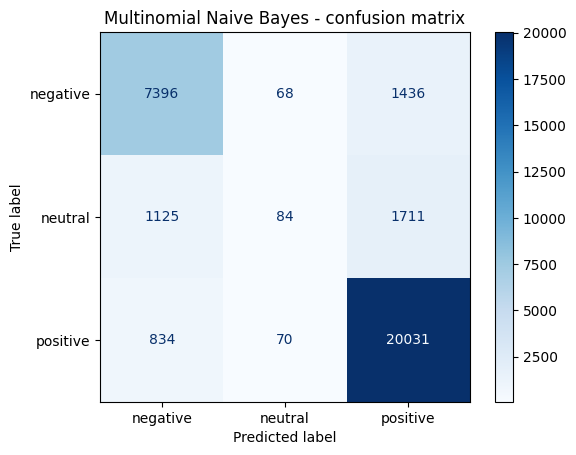

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = ["negative", "neutral", "positive"]
cm = confusion_matrix(y_test, y_pred, labels=labels)
print(pd.DataFrame(cm, index=[f"true {l}" for l in labels], columns=[f"pred {l}" for l in labels]))

ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", values_format="d")
plt.title("Multinomial Naive Bayes - confusion matrix")
plt.show()

### Extra – handling the class imbalance
`ComplementNB` is a Naive Bayes variant designed for imbalanced text data. Comparing it with `MultinomialNB` shows how much the minority (neutral) class can improve.

In [18]:
from sklearn.naive_bayes import ComplementNB

cnb = ComplementNB()
cnb.fit(X_train_tfidf, y_train)
y_pred_c = cnb.predict(X_test_tfidf)
print(f"ComplementNB accuracy: {accuracy_score(y_test, y_pred_c):.4f}\n")
print(classification_report(y_test, y_pred_c, digits=3))
print(pd.DataFrame(confusion_matrix(y_test, y_pred_c, labels=labels),
                   index=[f"true {l}" for l in labels], columns=[f"pred {l}" for l in labels]))

ComplementNB accuracy: 0.8232

              precision    recall  f1-score   support

    negative      0.687     0.923     0.788      8900
     neutral      0.348     0.077     0.126      2920
    positive      0.919     0.885     0.902     20935

    accuracy                          0.823     32755
   macro avg      0.651     0.628     0.605     32755
weighted avg      0.805     0.823     0.802     32755

               pred negative  pred neutral  pred positive
true negative           8213           117            570
true neutral            1638           224           1058
true positive           2106           303          18526


In [19]:
# Most informative words per class (largest log-probabilities relative to the other classes)
feature_names = np.array(tfidf.get_feature_names_out())
for i, cls in enumerate(nb.classes_):
    others = np.delete(nb.feature_log_prob_, i, axis=0).mean(axis=0)
    top = np.argsort(nb.feature_log_prob_[i] - others)[-12:][::-1]
    print(f"{cls:<9}: {', '.join(feature_names[top])}")

negative : worst phone, waste money, want money, waste, not waste, lost money, time money, money back, never worked, dont buy, working month, piece junk
neutral  : three star, sure good, ok product, ok price, phone okay, work okay, ok phone, average phone, bit disappointed, work ok, phone ok, okay phone
positive : excellent product, love new, love love, son love, excellent phone, wife love, excelent, excelente, daughter love, excellent, great product, love great


## Observations

**Data:** 413,840 reviews were loaded. After removing rows without a review and **duplicate reviews**, 163,958 remain. Duplicates were a big problem in this dataset (the same review is often posted for several phone variants); keeping them would put identical reviews in both train and test and inflate the score. The classes are imbalanced: 64 % positive, 27 % negative, only **9 % neutral**.

**Results on the test set (32,755 reviews)**

| Model | Accuracy | F1 negative | F1 neutral | F1 positive | Macro F1 |
|---|---|---|---|---|---|
| MultinomialNB | **0.840** | 0.810 | 0.053 | 0.908 | 0.591 |
| ComplementNB | 0.823 | 0.788 | 0.126 | 0.902 | 0.605 |

**What the confusion matrix shows**
- Positive reviews are recognised very well (20,031 of 20,935 correct, recall 0.96). Negative reviews are also good (recall 0.83).
- **Neutral reviews are almost never predicted**: only 84 of 2,920 are correct (recall 0.03). They are split between *negative* (1,125) and *positive* (1,711). Naive Bayes favours the large classes through its class priors, and 3-star reviews usually mix praise and complaints, so their words look like the other two classes.
- **Accuracy (84 %) hides this problem.** A model that ignores the neutral class completely can still reach a high accuracy, so the macro-averaged F1 (0.59) is the more honest summary.
- ComplementNB, designed for imbalanced text, finds more neutral reviews (recall 0.08) and many more negatives (recall 0.92). In return it has slightly lower accuracy, and its macro F1 is slightly better.

**The learned phrases make sense:** negative → *worst phone, waste money, money back, never worked, piece junk*; neutral → *three star, ok product, phone okay, average phone, bit disappointed*; positive → *excellent product, love, great product*. The bigrams (`ngram_range=(1, 2)`) and keeping negations matter: *"not waste"* and *"never worked"* are only useful as phrases.

**Pre-processing side effect:** WordNet lemmatizes *us* to *u* (visible in the first before/after example). Lemmatizers without POS information make small mistakes like this.

**Compared with the Disneyland example:** the linear SVM there also reached 0.84 accuracy with the same weakness on the neutral class (F1 0.26). It also took about 20 minutes to train on 34k reviews, while Naive Bayes trains on 131k reviews in under a second.